In [246]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [247]:
data = pd.read_csv("steam_data/steam-200k.csv", header=None)
data.columns = ['user', 'game', 'action', 'hours','0']

data = data[data['action'] == 'play'][['user', 'game', 'hours']]
data = data.groupby(['game', 'user'])[['hours']].agg(sum).reset_index()

/tmp/ipykernel_9531/1455464306.py:5: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  data = data.groupby(['game', 'user'])[['hours']].agg(sum).reset_index()


In [248]:
(data.groupby('game')[['hours']].agg(sum) > 100).mean()

/tmp/ipykernel_9531/3236372768.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  (data.groupby('game')[['hours']].agg(sum) > 100).mean()


hours    0.248056
dtype: float64

In [251]:
st = data.groupby('game')[['hours']].agg(sum)
st = st[st['hours'] > 1000]
st

data = data[data['game'].apply(lambda x: x in st.index)]

/tmp/ipykernel_9531/1897816759.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  st = data.groupby('game')[['hours']].agg(sum)


In [253]:
data

,game,user,hours
92,7 Days to Die,298950,14.3
93,7 Days to Die,9180659,6.2
94,7 Days to Die,10599862,0.3
95,7 Days to Die,17414305,160.0
96,7 Days to Die,17497581,28.0
...,...,...,...
70185,Zombie Panic Source,234467038,1.3
70186,Zombie Panic Source,244290943,3.5
70187,Zombie Panic Source,245046657,1.4
70188,Zombie Panic Source,256645945,0.5


In [254]:
data[data['user'] == 151603712].sort_values('hours', ascending=False)

,game,user,hours
60804,The Elder Scrolls V Skyrim,151603712,273.0
27282,Fallout 4,151603712,87.0
54368,Spore,151603712,14.9
27564,Fallout New Vegas,151603712,12.1
37940,Left 4 Dead 2,151603712,8.9
45004,Path of Exile,151603712,8.1
37288,Left 4 Dead,151603712,3.3
58152,Team Fortress 2,151603712,2.8
63796,Tomb Raider,151603712,2.5
5895,BioShock Infinite,151603712,1.3


In [255]:
hours = data.groupby('user')[['hours']].agg(total_hours=('hours', sum)).sort_values('total_hours')#.tail(20)

/tmp/ipykernel_9531/3482298468.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  hours = data.groupby('user')[['hours']].agg(total_hours=('hours', sum)).sort_values('total_hours')#.tail(20)


In [256]:
# data[data['user'] == 57433226].sort_values('hours', ascending=False)

In [257]:
hours

,total_hours
user,
144736,0.1
258086009,0.1
27115822,0.1
120853104,0.1
174813416,0.1
...,...
52731290,9104.9
153382649,9640.0
10599862,10196.1


In [258]:
joined_data = data.set_index('user').join(hours)
joined_data['game_p'] = joined_data['hours'] / joined_data['total_hours']

In [259]:
joined_data

,game,hours,total_hours,game_p
user,,,,
298950,7 Days to Die,14.3,3518.1,0.004065
9180659,7 Days to Die,6.2,1121.6,0.005528
10599862,7 Days to Die,0.3,10196.1,0.000029
17414305,7 Days to Die,160.0,832.4,0.192215
17497581,7 Days to Die,28.0,799.0,0.035044
...,...,...,...,...
234467038,Zombie Panic Source,1.3,34.3,0.037901
244290943,Zombie Panic Source,3.5,131.8,0.026555
245046657,Zombie Panic Source,1.4,1.4,1.000000


In [260]:
joined_data.loc[151603712].sort_values('hours', ascending=False)

,game,hours,total_hours,game_p
user,,,,
151603712,The Elder Scrolls V Skyrim,273.0,419.1,0.651396
151603712,Fallout 4,87.0,419.1,0.207588
151603712,Spore,14.9,419.1,0.035552
151603712,Fallout New Vegas,12.1,419.1,0.028871
151603712,Left 4 Dead 2,8.9,419.1,0.021236
151603712,Path of Exile,8.1,419.1,0.019327
151603712,Left 4 Dead,3.3,419.1,0.007874
151603712,Team Fortress 2,2.8,419.1,0.006681
151603712,Tomb Raider,2.5,419.1,0.005965


In [261]:
joined_data['interest'] = joined_data['game_p'] > 0.1

In [262]:
joined_data['interest'].mean()

np.float64(0.35715327048304013)

In [263]:
len(data['user'].unique())

10518

In [264]:
len(data['game'].unique())

262

In [265]:
x = joined_data.reset_index().pivot(index=['user'], columns=['game'], values=['interest'])

In [266]:
x

interest                                    \
game      7 Days to Die APB Reloaded ARK Survival Evolved   
user                                                        
5250                NaN          NaN                  NaN   
76767               NaN          NaN                  NaN   
86540               NaN          NaN                  NaN   
144736              NaN          NaN                  NaN   
181212              NaN          NaN                  NaN   
...                 ...          ...                  ...   
309404240           NaN          NaN                  NaN   
309434439           NaN          NaN                  NaN   
309626088           NaN          NaN                  NaN   
309824202           NaN          NaN                  NaN   
309903146           NaN          NaN                  NaN   

                                                             \
game      AdVenture Capitalist Age of Empires II HD Edition   
user                                                          
5250                       NaN                          NaN   
76767                      NaN                        False   
86540                      NaN                        False   
144736                     NaN                          NaN   
181212                     NaN                          NaN   
...                        ...                          ...   
309404240                False                          NaN   
309434439                  NaN                          NaN   
309626088                  NaN                         True   
309824202                  NaN                          NaN   
309903146                  NaN                          NaN   

                                                                               \
game      Age of Empires III Complete Collection Age of Wonders III Alan Wake   
user                                                                            
5250                                         NaN                NaN       NaN   
76767                                        NaN                NaN       NaN   
86540                                        NaN                NaN     False   
144736                                       NaN                NaN       NaN   
181212                                       NaN                NaN       NaN   
...                                          ...                ...       ...   
309404240                                    NaN                NaN       NaN   
309434439                                    NaN                NaN       NaN   
309626088                                    NaN                NaN       NaN   
309824202                                    NaN                NaN       NaN   
309903146                                    NaN                NaN       NaN   

                                                      ...           \
game      Alien Swarm America's Army Proving Grounds  ... Warframe   
user                                                  ...            
5250            False                            NaN  ...      NaN   
76767           False                            NaN  ...      NaN   
86540             NaN                            NaN  ...      NaN   
144736            NaN                            NaN  ...      NaN   
181212            NaN                            NaN  ...      NaN   
...               ...                            ...  ...      ...   
309404240         NaN                            NaN  ...      NaN   
309434439         NaN                            NaN  ...      NaN   
309626088         NaN                            NaN  ...      NaN   
309824202         NaN                            NaN  ...      NaN   
309903146         NaN                            NaN  ...      NaN   

                                                     \
game      Wargame AirLand Battle Wargame Red Dragon   
user                                               

In [267]:
len(joined_data.reset_index()[['user', 'game']])

41156

In [268]:
len(joined_data.reset_index()[['user', 'game']].drop_duplicates())

41156

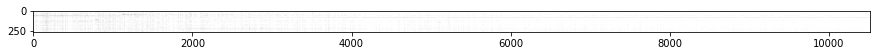

In [269]:
plt.figure(figsize=(15, 5))
plt.imshow(x.values.astype('float').T)

In [271]:
x.isna().mean().mean()

np.float64(0.9850652244280615)

In [272]:
# 1. Ігрии: The Elder Scrolls V Skyrim; Fallout 4
# 2. Інтерес: зіцікавлені, або ні, не купляв

In [273]:
joined_data

,game,hours,total_hours,game_p,interest
user,,,,,
298950,7 Days to Die,14.3,3518.1,0.004065,False
9180659,7 Days to Die,6.2,1121.6,0.005528,False
10599862,7 Days to Die,0.3,10196.1,0.000029,False
17414305,7 Days to Die,160.0,832.4,0.192215,True
17497581,7 Days to Die,28.0,799.0,0.035044,False
...,...,...,...,...,...
234467038,Zombie Panic Source,1.3,34.3,0.037901,False
244290943,Zombie Panic Source,3.5,131.8,0.026555,False
245046657,Zombie Panic Source,1.4,1.4,1.000000,True


In [274]:
x_slice = x['interest'][['The Elder Scrolls V Skyrim', 'Fallout 4']].fillna(-1)

In [275]:
x_slice

game,The Elder Scrolls V Skyrim,Fallout 4
user,,
5250,-1,-1
76767,-1,-1
86540,True,-1
144736,-1,-1
181212,-1,-1
...,...,...
309404240,-1,-1
309434439,-1,-1
309626088,-1,-1


In [276]:
for c in x_slice.columns:
    x_slice

In [277]:
o_data = x_slice.value_counts().reset_index().pivot(index=['The Elder Scrolls V Skyrim'], columns='Fallout 4', values='count')

In [278]:
o_data

Fallout 4,-1,False,True
The Elder Scrolls V Skyrim,,,
-1,9776,40,25
False,277,63,8
True,298,20,11


In [279]:
e_data = o_data.values.sum(axis=1, keepdims=True) * o_data.values.sum(axis=0, keepdims=True)
e_data = e_data / o_data.sum().sum()

In [280]:
o_data.sum().sum()

np.int64(10518)

In [281]:
stat = ((o_data - e_data) ** 2 / e_data).values.sum()
stat

np.float64(1088.6404205809931)

In [282]:
from scipy.stats import chi2

alpha = 0.05

In [283]:
q = chi2((3 - 1) * (3 - 1)).ppf(1 - alpha)
q

np.float64(9.487729036781154)

In [284]:
print("Приймаємо Н_{}".format(int(stat > q)))

Приймаємо Н_1


In [285]:
stat, q

(np.float64(1088.6404205809931), np.float64(9.487729036781154))

In [286]:
p_level = 1 - chi2.cdf(stat, df=(3 - 1) * (3 - 1))
p_level

np.float64(0.0)

In [287]:
from scipy.stats import chi2_contingency

In [288]:
res = chi2_contingency(o_data)

In [289]:
res.statistic

np.float64(1088.6404205809931)

In [290]:
print("Приймаємо Н_{}".format(res.pvalue < 0.05))

Приймаємо Н_True


In [291]:
res.pvalue

np.float64(2.194764242286979e-234)

In [292]:
from tqdm import tqdm
xi = x['interest'].fillna(-1)

In [293]:
pvalues = []
game1 = 'The Elder Scrolls V Skyrim'
for game2 in tqdm(list(x['interest'].columns)):
    if game2 == game1: continue
    x_slice = xi[[game1, game2]]
    o_data = x_slice.value_counts().reset_index().pivot(index=[game2], columns=game, values='count')
    o_data = o_data.fillna(0)
    res = chi2_contingency(o_data)
    pvalues.append({'game1': game1, 'game2': game2, 'pval': res.pvalue})

100%|██████████| 262/262 [00:01<00:00, 237.30it/s]


In [294]:
pd.DataFrame(pvalues).sort_values('pval')

,game1,game2,pval
33,The Elder Scrolls V Skyrim,Borderlands 2,0.000000e+00
179,The Elder Scrolls V Skyrim,Portal 2,0.000000e+00
100,The Elder Scrolls V Skyrim,Fallout New Vegas,0.000000e+00
202,The Elder Scrolls V Skyrim,Sid Meier's Civilization V,1.084420e-307
75,The Elder Scrolls V Skyrim,Dishonored,1.959604e-292
...,...,...,...
82,The Elder Scrolls V Skyrim,Dragon Nest Europe,3.600813e-02
174,The Elder Scrolls V Skyrim,Perpetuum,5.739115e-02
105,The Elder Scrolls V Skyrim,Football Manager 2009,5.533764e-01
85,The Elder Scrolls V Skyrim,Eastside Hockey Manager,9.661848e-01


In [295]:
pd.DataFrame(pvalues).sort_values('pval').head(20)

,game1,game2,pval
33,The Elder Scrolls V Skyrim,Borderlands 2,0.000000e+00
179,The Elder Scrolls V Skyrim,Portal 2,0.000000e+00
100,The Elder Scrolls V Skyrim,Fallout New Vegas,0.000000e+00
202,The Elder Scrolls V Skyrim,Sid Meier's Civilization V,1.084420e-307
75,The Elder Scrolls V Skyrim,Dishonored,1.959604e-292
221,The Elder Scrolls V Skyrim,Terraria,3.710809e-289
29,The Elder Scrolls V Skyrim,BioShock Infinite,5.494461e-288
139,The Elder Scrolls V Skyrim,Left 4 Dead 2,1.002300e-278
229,The Elder Scrolls V Skyrim,The Walking Dead,8.446648e-251
96,The Elder Scrolls V Skyrim,FTL Faster Than Light,4.394522e-241


In [323]:
pd.DataFrame(pvalues).sort_values('pval').tail(20)

,game1,game2,pval
180,The Elder Scrolls V Skyrim,Prime World,0.000004
134,The Elder Scrolls V Skyrim,King's Bounty Warriors of the North,0.000006
241,The Elder Scrolls V Skyrim,Train Simulator,0.000011
58,The Elder Scrolls V Skyrim,Counter-Strike Nexon Zombies,0.000011
111,The Elder Scrolls V Skyrim,Football Manager 2015,0.000232
104,The Elder Scrolls V Skyrim,Farming Simulator 2013,0.000695
56,The Elder Scrolls V Skyrim,Counter-Strike Condition Zero,0.001611
25,The Elder Scrolls V Skyrim,Battle Nations,0.001811
210,The Elder Scrolls V Skyrim,Spiral Knights,0.003152
68,The Elder Scrolls V Skyrim,Day of Defeat,0.003267


In [301]:
d = pd.DataFrame(pvalues)
d[d['pval'] > 0.95].head(20)

,game1,game2,pval
85,The Elder Scrolls V Skyrim,Eastside Hockey Manager,0.966185
258,The Elder Scrolls V Skyrim,X-Plane 10 Global - 64 Bit,0.991354


In [302]:
x_slice

game,The Elder Scrolls V Skyrim,Zombie Panic Source
user,,
5250,-1,-1
76767,-1,-1
86540,True,-1
144736,-1,-1
181212,-1,-1
...,...,...
309404240,-1,-1
309434439,-1,-1
309626088,-1,-1


In [321]:
# Strong dependancy
# game2 = 'Borderlands 2'
# game2 = "Sid Meier's Civilization V"
# game2 = "Fallout New Vegas"
# game2 = "Portal 2"
# game2 = 'Terraria'
game2 = 'Football Manager 2016'

# independence
# game2 = 'Football Manager 2009'
# game2 = 'Perpetuum'
# game2 = 'Farming Simulator 15'
# game2 = 'Transformice'



x_slice = xi[[game1, game2]]
o_data = x_slice.value_counts().reset_index().pivot(index=[game1], columns=[game2], values='count')

In [322]:
o_data

Football Manager 2016,-1,False,True
The Elder Scrolls V Skyrim,,,
-1,9818.0,12.0,11.0
False,344.0,3.0,1.0
True,329.0,NaN,NaN
